# Experiments: EDA tables, controlled feature comparisons, OOF error analysis

DSC PJATK Catalogue Quality Challenge, Team 2. This notebook produces every number in Sections 3 and 5
of the report: the EDA tables, the two controlled feature comparisons and the analysis of five
out-of-fold errors required by Rules section 4. The reference model is `ref`, the final model of
`02_model.ipynb`.

**Protocol (identical for every configuration)**
- Folds: the organisers' seller-disjoint assignment, SHA-256(`42:<seller_id>`)[:16] mod 5. The
  `fold_assignment_sha256` printed below must equal `dda65b9d...` from the baseline.
- Model: LightGBM with fixed hyper-parameters and a **fixed number of trees (400)**. There is no early
  stopping, because early stopping on the held-out fold would select the model with validation labels.
- Every learned statistic (product-phrase category purity and modal category, modal pack size,
  price and weight medians and MADs, categorical levels) is fitted **inside each training fold** and
  only then applied to the held-out fold and to the test set.
- All 16,000 training rows are used. The seed is fixed and LightGBM runs with `deterministic=True`.
- Reported per configuration: pooled OOF ROC-AUC, OOF average precision, per-fold ROC-AUC and
  runtime. The difference between configurations comes with a 95% seller-level bootstrap interval
  (whole sellers are resampled, because sellers are the grouping unit).

**Feature groups**

| group | content | learned in fold? |
|---|---|---|
| base | log price / weight / pack size, per-item ratios, text lengths, missingness flags, category word in text, categorical `declared_category`, `brand`, `condition` | categorical levels only |
| quantity | main-item count parsed from the text, free-accessory count, mismatch with `pack_size` | no (deterministic parser) |
| phrase | per-product category purity, contradiction with the dominant category, modal pack size | yes |
| anomaly | robust z-scores of price and weight (package and per item) against the product's median, per product and per product×category | yes |
| composite | `rule_score`, `extreme_AND_mismatch`, built **only** from the active groups | derived |

Both comparisons share one reference configuration, `ref` (all groups, team quantity parser).

In [1]:
# Pipeline code (inlined from catalogue_pipeline.py in the repository)
"""Catalogue quality pipeline: features, seller-disjoint CV, inference, controlled comparisons.

Same features and LightGBM settings as the team's original pipeline, with the validation fixes:
  * fixed number of trees; the original early-stopped on the held-out fold, i.e. chose the
    model size with validation labels;
  * every learned statistic (phrase purity, modal category, modal pack size, price/weight
    medians and MADs, categorical levels) is fitted on the training fold only; the original
    computed price/weight medians on all rows of each frame (validation and test included)
    and categorical levels on train+test;
  * deterministic LightGBM with a fixed thread count, library versions recorded.

Run:  python catalogue_pipeline.py --data-dir data/public --out results

Features are organised in named groups so a comparison changes exactly one group:
  base      raw attributes, lengths, missingness flags, category word in text, categoricals
  quantity  main-item count parsed from text vs pack_size   (extractor is swappable)
  phrase    fold-fitted per-product statistics: category purity/contradiction, modal pack size
  anomaly   fold-fitted robust z-scores of price and weight (package and per item) per product
  composite rule_score / extreme_AND_mismatch, built only from the groups that are active
"""
import hashlib
import json
import platform
import re
import time
from pathlib import Path

import lightgbm as lgb
import numpy as np
import pandas as pd
import sklearn
from sklearn.metrics import average_precision_score, roc_auc_score

SEED = 42
N_TREES = 400
CATS = ['declared_category', 'brand', 'condition']
WORD2NUM = {'one': 1, 'two': 2, 'three': 3, 'four': 4, 'five': 5, 'six': 6, 'seven': 7,
            'eight': 8, 'nine': 9, 'ten': 10, 'zero': 0, 'single': 1}
NUMW = 'one|two|three|four|five|six|seven|eight|nine|ten'


# --------------------------------------------------------------------------- folds
def fold_assignment(sellers, n_splits=5, seed=SEED):
    """Organisers' seller-disjoint folds: SHA-256('42:<seller_id>')[:16] mod 5. Label-free."""
    return np.array([int(hashlib.sha256(f'{seed}:{s}'.encode('utf-8')).hexdigest()[:16], 16)
                     % n_splits for s in sellers.astype(str)])


# --------------------------------------------------------------- quantity extractors
def qty_first_pcs(text):
    """Starter heuristic from the organisers' baseline: first '<digits> pcs' in the text.
    Picks up free accessories and ignores quantities written as words."""
    m = re.search(r'(\d+)\s*pcs', text)
    return int(m.group(1)) if m else None


def qty_main_items(text):
    """Team parser: removes the free-accessory sentence, then tries main-item patterns
    (digits and number words) in a fixed priority order."""
    t = re.sub(r'also includes \d+ pcs? of free accessory[^.]*\.?', ' ', text)
    t = re.sub(r'free accessory[^.]*\.?', ' ', t)
    pats = [r'included main items:\s*(\d+)',
            r'(\d+)\s+individually boxed main items', rf'({NUMW})\s+individually boxed main items',
            r'(\d+)\s+main items', rf'({NUMW})\s+main items',
            rf'pack of ({NUMW}) main items', r'pack of (\d+) main items',
            r'bundle quantity:\s*(\d+)', r'(\d+)\s*-?pack', r'sold as a (\d+)-pack',
            r'\(quantity\s*(\d+)\)', r'quantity\s*(\d+)', r'(\d+)\s*units',
            r'package contains\s*(\d+)', r'(\d+)\s*pcs', rf'pack of ({NUMW})']
    for p in pats:
        m = re.search(p, t)
        if m:
            v = m.group(1)
            return WORD2NUM.get(v) if v.isalpha() else int(v)
    return None


EXTRACTORS = {'first_pcs': qty_first_pcs, 'main_items': qty_main_items}


# ------------------------------------------------------------ deterministic features
def product_phrase(title, desc):
    """Product noun: '<noun> by <Brand>' in the description, else the title head."""
    m = re.search(r'([a-z][a-z\s\-/]{2,40}?)\s+by\s+(?:mira|noro|velto|tenso|aster)', desc)
    if m:
        return m.group(1).strip()
    m = re.search(r'([a-z][a-z\s\-/]{2,40}?)\s*[—\-/]', title)
    return m.group(1).strip() if m else ''


def base_frame(df, extractor):
    """Label-free, row-wise features. Nothing is learned here."""
    x = df.copy()
    title = x.title.fillna('').astype(str).str.lower()
    desc = x.description.fillna('').astype(str).str.lower()
    x['text'] = (title + ' ' + desc).str.replace(r'\s+', ' ', regex=True).str.strip()
    # base
    x['text_is_short'] = (x.text.str.len() < 20).astype(int)
    for c in ['title', 'description', 'declared_category', 'brand', 'condition']:
        x['isna_' + c] = x[c].isna().astype(int)
    x['isna_price'] = x.price_pln.isna().astype(int)
    x['isna_weight'] = x.shipping_weight_kg.isna().astype(int)
    for c in ['price_pln', 'shipping_weight_kg', 'pack_size']:
        x['log_' + c] = np.log1p(x[c].clip(lower=0))
    x['price_per_item'] = np.log1p(x.price_pln / x.pack_size.clip(lower=1))
    x['mass_per_item'] = np.log1p(x.shipping_weight_kg / x.pack_size.clip(lower=1))
    x['price_per_weight'] = np.log1p(x.price_pln / (x.shipping_weight_kg + 1e-3))
    x['title_len'], x['desc_len'] = title.str.len(), desc.str.len()
    x['desc_title_ratio'] = x.desc_len / (x.title_len + 1)
    cat = x.declared_category.fillna('missing').astype(str).str.lower()
    x['category_in_text'] = [int(c in t) for c, t in zip(cat, x.text)]
    # quantity (depends on the extractor)
    x['main_items'] = pd.to_numeric(x.text.map(EXTRACTORS[extractor]), errors='coerce')
    m = re.compile(r'also includes (\d+) pcs? of free accessory')
    x['free_acc'] = x.text.map(lambda t: int(m.search(t).group(1)) if m.search(t) else 0)
    pk, mi = x.pack_size, x.main_items
    x['mvp_mismatch'] = (pk.notna() & mi.notna() & (pk != mi)).astype(int)
    x['pack_vs_main'] = pk - mi
    x['pack_vs_main_abs'] = (pk - mi).abs()
    # product key used by the fold-fitted groups
    x['product_phrase'] = [re.sub(r'\s+', ' ', product_phrase(t, d)).strip()
                           for t, d in zip(title, desc)]
    x['grp_pc'] = x.product_phrase + '||' + x.declared_category.astype(str)
    return x


GROUP_COLUMNS = {
    'base': ['log_price_pln', 'log_shipping_weight_kg', 'log_pack_size', 'price_per_item',
             'mass_per_item', 'price_per_weight', 'title_len', 'desc_len', 'desc_title_ratio',
             'isna_title', 'isna_description', 'isna_declared_category', 'isna_brand',
             'isna_condition', 'isna_price', 'isna_weight', 'category_in_text', 'text_is_short'],
    'quantity': ['main_items', 'free_acc', 'mvp_mismatch', 'pack_vs_main', 'pack_vs_main_abs'],
    'phrase': ['phrase_purity', 'cat_contradicts_strict', 'pack_anomaly_pp'],
    # 8 z-scores + 6 per-item flags + 3 summaries = 17 columns (as in the team's FEATS)
    'anomaly': [f'{v}_{k}' for v in ['price', 'weight', 'price_item', 'weight_item']
                for k in ['z_pp2', 'z_pc']]
               + [f'{v}_{k}' for v in ['price_item', 'weight_item']
                  for k in ['hi_pp2', 'extreme_pp2', 'extreme_pc']]
               + ['any_extreme_anom', 'anom_pp_minus_pc', 'anom_wt_pp_minus_pc'],
}
ANOM_VALUES = {
    'price': lambda d: d.price_pln,
    'weight': lambda d: d.shipping_weight_kg,
    'price_item': lambda d: d.price_pln / d.pack_size.clip(lower=1),
    'weight_item': lambda d: d.shipping_weight_kg / d.pack_size.clip(lower=1),
}


# ---------------------------------------------------------- fold-fitted feature groups
def fit_transform_fold(x_fit, frames, groups):
    """Fit per-product statistics on the training fold `x_fit` and apply them to each frame."""
    out = [f.copy() for f in frames]
    if 'phrase' in groups:
        def purity(s):
            s = s.dropna()
            if len(s) < 5:
                return (0.0, None)
            vc = s.value_counts(normalize=True)
            return (float(vc.iloc[0]), vc.index[0])
        st = x_fit.groupby('product_phrase').declared_category.agg(purity)
        pur = {p: v[0] for p, v in st.items()}
        modal = {p: v[1] for p, v in st.items()}
        pmode = x_fit.groupby('product_phrase').pack_size.agg(
            lambda s: s.dropna().mode().iloc[0] if s.notna().any() else np.nan).to_dict()
        for f in out:
            f['phrase_purity'] = f.product_phrase.map(pur).fillna(0.0)
            mc = f.product_phrase.map(modal)
            f['cat_contradicts_strict'] = ((f.phrase_purity >= 0.90) & mc.notna()
                                           & f.declared_category.notna()
                                           & (mc != f.declared_category)).astype(int)
            pm = f.product_phrase.map(pmode)
            f['pack_anomaly_pp'] = (pm.notna() & f.pack_size.notna()
                                    & (f.pack_size != pm)).astype(int)
    if 'anomaly' in groups:
        vc_pp = x_fit.product_phrase.value_counts()
        vc_pc = x_fit.grp_pc.value_counts()
        trusted_pp, trusted_pc = set(vc_pp[vc_pp >= 8].index), set(vc_pc[vc_pc >= 6].index)
        stats = {}
        for name, fn in ANOM_VALUES.items():
            v = fn(x_fit)
            for key in ['product_phrase', 'grp_pc']:
                med = v.groupby(x_fit[key]).median()
                mad = (v - x_fit[key].map(med)).abs().groupby(x_fit[key]).median()
                stats[name, key] = (med, mad)
        for f in out:
            for name, fn in ANOM_VALUES.items():
                v = fn(f)
                for key, suf in [('product_phrase', 'pp2'), ('grp_pc', 'pc')]:
                    med, mad = stats[name, key]
                    f[f'{name}_z_{suf}'] = (v - f[key].map(med)) / (f[key].map(mad) + 1e-6)
                zpp, zpc = f[f'{name}_z_pp2'].abs(), f[f'{name}_z_pc'].abs()
                ok_pp, ok_pc = f.product_phrase.isin(trusted_pp), f.grp_pc.isin(trusted_pc)
                f[f'{name}_hi_pp2'] = ((zpp > 4) & ok_pp).astype(int)
                f[f'{name}_extreme_pp2'] = ((zpp > 6) & ok_pp).astype(int)
                f[f'{name}_extreme_pc'] = ((zpc > 6) & ok_pc).astype(int)
            f['any_extreme_anom'] = (f.price_item_extreme_pp2 | f.weight_item_extreme_pp2
                                     | f.price_item_extreme_pc | f.weight_item_extreme_pc).astype(int)
            f['anom_pp_minus_pc'] = (f.price_item_z_pp2.abs() - f.price_item_z_pc.abs()).fillna(0)
            f['anom_wt_pp_minus_pc'] = (f.weight_item_z_pp2.abs() - f.weight_item_z_pc.abs()).fillna(0)
    # composite features use only the active groups
    for f in out:
        score = pd.Series(0.0, index=f.index)
        if 'quantity' in groups:
            score += 10.0 * f.mvp_mismatch
        if 'phrase' in groups:
            score += 5.0 * f.cat_contradicts_strict
        if 'anomaly' in groups:
            score += 2.0 * f.any_extreme_anom + f.price_item_hi_pp2 + f.weight_item_hi_pp2
        f['rule_score'] = score
        if {'quantity', 'anomaly'} <= set(groups):
            f['extreme_AND_mismatch'] = f.any_extreme_anom * f.mvp_mismatch
    # categorical levels learned on the training fold only
    for c in CATS:
        levels = pd.Categorical(x_fit[c].fillna('missing')).categories
        for f in out:
            f[c] = pd.Categorical(f[c].fillna('missing'), categories=levels)
    return out


def feature_list(groups):
    cols = [c for g in ['base', 'quantity', 'phrase', 'anomaly'] if g in groups
            for c in GROUP_COLUMNS[g]]
    cols.append('rule_score')
    if {'quantity', 'anomaly'} <= set(groups):
        cols.append('extreme_AND_mismatch')
    return cols + CATS


def make_model(fold):
    """Team LightGBM settings with a fixed number of trees, deterministic.
    The original also set subsample=0.85, which LightGBM ignores while subsample_freq=0
    (the default), so it is left out: the fitted model is the same."""
    return lgb.LGBMClassifier(n_estimators=N_TREES, learning_rate=0.03, num_leaves=95,
                              min_child_samples=20, colsample_bytree=0.85,
                              reg_lambda=1.0, objective='binary', verbosity=-1, n_jobs=4,
                              deterministic=True, force_row_wise=True, random_state=SEED + fold)


# ----------------------------------------------------------------------------- CV run
def run_cv(train, test, extractor, groups, name, out_dir, data_dir=None):
    started = time.perf_counter()
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    y = train.target.to_numpy()
    x = base_frame(train.drop(columns='target'), extractor)
    xt = base_frame(test, extractor)
    folds = fold_assignment(train.seller_id)
    cols = feature_list(groups)
    oof, pred, per_fold, fold_sec = np.zeros(len(train)), np.zeros(len(test)), [], []
    for k in range(5):
        t0 = time.perf_counter()
        fit, val = np.flatnonzero(folds != k), np.flatnonzero(folds == k)
        assert set(train.seller_id.iloc[fit]).isdisjoint(train.seller_id.iloc[val])
        xf, xv, xtt = fit_transform_fold(x.iloc[fit], [x.iloc[fit], x.iloc[val], xt], groups)
        model = make_model(k + 1).fit(xf[cols], y[fit], categorical_feature=CATS)
        oof[val] = model.predict_proba(xv[cols])[:, 1]
        pred += model.predict_proba(xtt[cols])[:, 1] / 5
        per_fold.append(float(roc_auc_score(y[val], oof[val])))
        fold_sec.append(time.perf_counter() - t0)
    report = {
        'name': name, 'extractor': extractor, 'groups': list(groups), 'features': cols,
        'n_features': len(cols), 'oof_roc_auc': float(roc_auc_score(y, oof)),
        'oof_average_precision': float(average_precision_score(y, oof)),
        'fold_roc_auc': per_fold, 'mean_fold_roc_auc': float(np.mean(per_fold)),
        'std_fold_roc_auc': float(np.std(per_fold)), 'fold_seconds': fold_sec,
        'elapsed_seconds': time.perf_counter() - started, 'seed': SEED, 'n_trees': N_TREES,
        'versions': {'python': platform.python_version(), 'numpy': np.__version__,
                     'pandas': pd.__version__, 'sklearn': sklearn.__version__,
                     'lightgbm': lgb.__version__},
        'data_sha256': ({f: hashlib.sha256((Path(data_dir) / f).read_bytes()).hexdigest()
                         for f in ['train.csv', 'test.csv', 'sample_submission.csv']}
                        if data_dir else None),
        'fold_assignment_sha256': hashlib.sha256(
            pd.DataFrame({'id': train.id, 'fold': folds + 1}).to_csv(index=False, lineterminator='\n')
            .encode('utf-8')).hexdigest(),
    }
    pd.DataFrame({'id': train.id, 'seller_id': train.seller_id, 'target': y,
                  'prediction': oof, 'fold': folds + 1}).to_csv(out_dir / f'oof_{name}.csv', index=False)
    pd.DataFrame({'id': test.id, 'target': pred}).to_csv(out_dir / f'submission_{name}.csv', index=False)
    (out_dir / f'cv_{name}.json').write_text(json.dumps(report, indent=2))
    return report


def seller_bootstrap_diff(oof_a, oof_b, n_boot=1000, seed=SEED):
    """95% interval of AUC(b) - AUC(a), resampling whole sellers (the grouping unit)."""
    a = oof_a.set_index('id')
    b = oof_b.set_index('id').loc[a.index]
    sellers = a.seller_id.unique()
    idx = a.groupby('seller_id').indices
    rng = np.random.default_rng(seed)
    y, pa, pb = a.target.to_numpy(), a.prediction.to_numpy(), b.prediction.to_numpy()
    diffs = []
    for _ in range(n_boot):
        rows = np.concatenate([idx[s] for s in rng.choice(sellers, len(sellers))])
        diffs.append(roc_auc_score(y[rows], pb[rows]) - roc_auc_score(y[rows], pa[rows]))
    return float(np.percentile(diffs, 2.5)), float(np.percentile(diffs, 97.5))


CONFIGS = {
    # shared reference configuration for both comparisons
    'ref': ('main_items', ('base', 'quantity', 'phrase', 'anomaly')),
    # comparison 1: only the quantity extractor changes
    'c1_first_pcs': ('first_pcs', ('base', 'quantity', 'phrase', 'anomaly')),
    # comparison 2: only the price/weight anomaly group is removed
    'c2_no_anomaly': ('main_items', ('base', 'quantity', 'phrase')),
}


FINAL = 'ref'   # configuration used for the Kaggle submission and the error analysis


def resolve_data_dir():
    for p in [Path('data/public'), Path('data'), *sorted(Path('/kaggle/input').rglob('train.csv'))]:
        d = p if p.is_dir() else p.parent
        if (d / 'train.csv').exists() and (d / 'sample_submission.csv').exists():
            return d
    raise FileNotFoundError('competition data not found; pass --data-dir')


def make_submission(data_dir, out_dir, config=FINAL):
    """Seller-disjoint CV of the chosen configuration + test predictions (mean of 5 fold models)."""
    data_dir, out_dir = Path(data_dir), Path(out_dir)
    train = pd.read_csv(data_dir / 'train.csv')
    test = pd.read_csv(data_dir / 'test.csv')
    sample = pd.read_csv(data_dir / 'sample_submission.csv')
    assert train.target.isin([0, 1]).all()
    assert set(train.seller_id).isdisjoint(test.seller_id)
    assert train.id.is_unique and test.id.is_unique and set(train.id).isdisjoint(test.id)
    assert sample.id.tolist() == test.id.tolist()
    extractor, groups = CONFIGS[config]
    report = run_cv(train, test, extractor, groups, config, out_dir, data_dir)
    pred = pd.read_csv(out_dir / f'submission_{config}.csv')
    assert pred.id.tolist() == sample.id.tolist()
    assert np.isfinite(pred.target).all() and pred.target.between(0, 1).all()
    sample['target'] = pred.target.to_numpy()
    sample.to_csv(out_dir / 'submission.csv', index=False)
    return report


In [2]:
from pathlib import Path
import pandas as pd

def resolve_data_dir():
    for p in [Path('data/public'), *sorted(Path('/kaggle/input').rglob('train.csv'))]:
        d = p if p.is_dir() else p.parent
        if (d / 'train.csv').exists() and (d / 'sample_submission.csv').exists():
            return d
    raise FileNotFoundError('competition data not found')

DATA = resolve_data_dir()
OUT = Path('/kaggle/working/comparisons') if Path('/kaggle/working').exists() else Path('results')
train, test = pd.read_csv(DATA / 'train.csv'), pd.read_csv(DATA / 'test.csv')
print(DATA, train.shape, test.shape)

data/public (16000, 11) (10000, 10)


## EDA tables (report Section 3)

Template sentences, quantity parsing, missingness and seller spread are computed on the training set.
Price, weight and category statistics are fitted on the training folds and evaluated on the held-out
sellers, so they are not in-sample.

In [3]:
import numpy as np
x_all = base_frame(train.drop(columns='target'), 'main_items')
desc = train.description.fillna('').str.lower()
promo = desc.str.contains('clearance promotion')
print(f"free-accessory sentence: {(x_all.free_acc > 0).mean():.1%} of listings")
print(f"promotion sentence: {promo.mean():.1%}; error rate with {train.target[promo].mean():.3f}, without {train.target[~promo].mean():.3f}")
for ext in ['first_pcs', 'main_items']:
    xq = base_frame(train.drop(columns='target'), ext)
    m = xq.mvp_mismatch == 1
    print(f"{ext:11s} parsed {xq.main_items.notna().mean():.1%} | count != pack_size: {int(m.sum())} | error rate among them {train.target[m].mean():.3f}")
print(f"mismatches as share of corrupted listings: {(x_all.mvp_mismatch == 1).sum() / train.target.sum():.1%}")

free-accessory sentence: 24.2% of listings
promotion sentence: 9.3%; error rate with 0.169, without 0.170


first_pcs   parsed 36.6% | count != pack_size: 2170 | error rate among them 0.206


main_items  parsed 99.9% | count != pack_size: 391 | error rate among them 1.000
mismatches as share of corrupted listings: 14.4%


In [4]:
# held-out (fold-fitted) features for every training listing
folds_all = fold_assignment(train.seller_id)
parts = []
for k in range(5):
    fit, val = np.flatnonzero(folds_all != k), np.flatnonzero(folds_all == k)
    parts.append(fit_transform_fold(x_all.iloc[fit], [x_all.iloc[fit], x_all.iloc[val]], CONFIGS['ref'][1])[1])
H = pd.concat(parts).sort_index()

bins, labels = [0, 2, 4, 6, 1e3, np.inf], ['<2', '2-4', '4-6', '6-1000', '>1000']
for c in ['price_item_z_pp2', 'weight_item_z_pp2']:
    b = pd.cut(H[c].abs(), bins, right=False, labels=labels)
    t = train.target.groupby(b, observed=True).agg(error_rate='mean', listings='size').T
    print(c); display(t.round(3))
c = H.cat_contradicts_strict == 1
print(f"category contradiction (purity >= 0.9): {int(c.sum())} listings, error rate {train.target[c].mean():.3f}")
pur = x_all[x_all.product_phrase != ''].groupby('product_phrase').declared_category.agg(
    lambda s: s.value_counts(normalize=True).iloc[0] if s.notna().any() else np.nan)
n = x_all.product_phrase.value_counts().reindex(pur.index)
big = pur[n >= 5]
print(f"phrases: {x_all.product_phrase.nunique()} | with >=5 listings: {len(big)}, median purity {big.median():.3f}, share >= 0.9: {(big >= 0.9).mean():.1%}")
display(train.groupby('declared_category').target.agg(error_rate='mean', listings='size').round(3))

price_item_z_pp2


price_item_z_pp2,<2,2-4,4-6,6-1000,>1000
error_rate,0.123,0.285,0.349,0.801,0.158
listings,11661.000,2360.000,312.000,336.000,38.000


weight_item_z_pp2


weight_item_z_pp2,<2,2-4,4-6,6-1000,>1000
error_rate,0.114,0.221,0.461,0.833,0.176
listings,10829.000,2414.000,685.000,419.000,34.000


category contradiction (purity >= 0.9): 634 listings, error rate 0.997
phrases: 404 | with >=5 listings: 180, median purity 0.941, share >= 0.9: 77.8%


,error_rate,listings
declared_category,,
audio,0.150,2535
beauty,0.159,1622
books,0.135,1691
computers,0.160,2759
garden,0.211,1331
kitchen,0.173,2253
music,0.366,735
pets,0.173,863
sport,0.140,1837


In [5]:
rows = []
for col in ['title', 'description', 'declared_category', 'brand', 'price_pln', 'shipping_weight_kg', 'pack_size']:
    m = train[col].isna()
    rows.append({'column': col, 'share_missing': m.mean(), 'error_rate_when_missing': train.target[m].mean(), 'n_missing': int(m.sum())})
display(pd.DataFrame(rows).round(3))

s = train.groupby('seller_id').target.mean()
p = train.target.mean()
rng = np.random.default_rng(0)
sim = [rng.binomial(20, p, s.size).std() / 20 for _ in range(200)]
print(f"seller error rate: min {s.min():.2f}, max {s.max():.2f}, observed std {s.std():.3f}, "
      f"binomial-only std 95% range {np.percentile(sim, 2.5):.3f} to {np.percentile(sim, 97.5):.3f}")

,column,share_missing,error_rate_when_missing,n_missing
0,title,0.029,0.149,470
1,description,0.042,0.150,680
2,declared_category,0.023,0.182,374
3,brand,0.059,0.155,947
4,price_pln,0.039,0.188,623
5,shipping_weight_kg,0.060,0.175,962
6,pack_size,0.030,0.181,485


seller error rate: min 0.00, max 0.60, observed std 0.098, binomial-only std 95% range 0.080 to 0.088


## Reference configuration

`ref` uses all feature groups and the team parser `qty_main_items`.

In [6]:
reports, oofs = {}, {}
def run(name):
    extractor, groups = CONFIGS[name]
    reports[name] = run_cv(train, test, extractor, groups, name, OUT)
    oofs[name] = pd.read_csv(OUT / f'oof_{name}.csv')
    r = reports[name]
    print(f"{name:14s} OOF AUC={r['oof_roc_auc']:.4f}  AP={r['oof_average_precision']:.4f}  "
          f"folds={[round(v, 4) for v in r['fold_roc_auc']]}  time={r['elapsed_seconds']:.1f}s  "
          f"features={r['n_features']}")

run('ref')
assert reports['ref']['fold_assignment_sha256'].startswith('dda65b9df2a8')
print('versions:', reports['ref']['versions'])

ref            OOF AUC=0.9688  AP=0.9260  folds=[0.9671, 0.9644, 0.9741, 0.9687, 0.9694]  time=49.5s  features=48
versions: {'python': '3.13.17', 'numpy': '2.1.3', 'pandas': '2.3.3', 'sklearn': '1.6.1', 'lightgbm': '4.6.0'}


## Comparison 1: quantity extraction

**Hypothesis (stated before running).** The organisers' starter heuristic takes the first
`<number> pcs` in the text. It counts free accessories ("Also includes 3 pcs of free accessory
pieces") as items and misses quantities written as words or as `pack of`, `-pack`, `units`. Its
mismatch flag with `pack_size` should therefore be mostly noise. Replacing it with a parser that
removes the accessory sentence and reads all main-item phrasings should make the mismatch flag a
precise signal for quantity corruptions and improve the ranking.

**Single change.** Only the function that extracts the main-item count: `qty_first_pcs` (variant)
vs `qty_main_items` (reference). Every quantity feature (`main_items`, `mvp_mismatch`,
`pack_vs_main`, `pack_vs_main_abs`) and the quantity term of `rule_score` are recomputed from that
count. Model, hyper-parameters, rows, folds and all other groups stay the same.

In [7]:
run('c1_first_pcs')
for ext in ['first_pcs', 'main_items']:
    xq = base_frame(train.drop(columns='target'), ext)
    m = xq.mvp_mismatch == 1
    print(f"{ext:11s} count found in {xq.main_items.notna().mean():.1%} of listings | "
          f"mismatch flagged on {int(m.sum())} listings | target rate when flagged {train.target[m].mean():.3f} "
          f"| when not flagged {train.target[~m].mean():.3f}")

c1_first_pcs   OOF AUC=0.9608  AP=0.9066  folds=[0.9563, 0.9583, 0.9696, 0.9571, 0.9626]  time=49.0s  features=48


first_pcs   count found in 36.6% of listings | mismatch flagged on 2170 listings | target rate when flagged 0.206 | when not flagged 0.164


main_items  count found in 99.9% of listings | mismatch flagged on 391 listings | target rate when flagged 1.000 | when not flagged 0.149


## Comparison 2: price and weight anomaly group

**Hypothesis (stated before running).** A corrupted package price or shipping weight should sit far
from what is typical for the same product. Raw log price and weight alone mix very different products
(a cable and an amplifier), so a deviation from the product's own fold-fitted median should expose
price and weight corruptions that the other groups cannot see. Removing the group should lower the
ranking quality.

**Single change.** The `anomaly` group (robust z-scores and the flags derived from them, 17 columns)
is removed, together with its terms in the composite features (`rule_score` loses
`2·any_extreme_anom + price_item_hi_pp2 + weight_item_hi_pp2`, and `extreme_AND_mismatch` is
dropped). The quantity parser, model, hyper-parameters, rows, folds and other groups stay the same.
Raw price and weight features in `base` are kept, so the comparison measures what the
**product-relative** view adds over the raw values.

In [8]:
run('c2_no_anomaly')

c2_no_anomaly  OOF AUC=0.9200  AP=0.8466  folds=[0.9103, 0.919, 0.921, 0.9268, 0.9223]  time=43.2s  features=30


## Results

In [9]:
rows = []
for variant, label in [('c1_first_pcs', 'C1: first-pcs heuristic instead of main-item parser'),
                       ('c2_no_anomaly', 'C2: without price/weight anomaly group')]:
    ref, var = reports['ref'], reports[variant]
    lo, hi = seller_bootstrap_diff(oofs['ref'], oofs[variant])
    rows.append({'comparison': label,
                 'ref OOF AUC': ref['oof_roc_auc'], 'variant OOF AUC': var['oof_roc_auc'],
                 'diff (variant-ref)': var['oof_roc_auc'] - ref['oof_roc_auc'],
                 '95% seller bootstrap': f'[{lo:+.4f}, {hi:+.4f}]',
                 'ref AP': ref['oof_average_precision'], 'variant AP': var['oof_average_precision'],
                 'ref time [s]': ref['elapsed_seconds'], 'variant time [s]': var['elapsed_seconds']})
summary = pd.DataFrame(rows)
display(summary.round(4))

per_fold = pd.DataFrame({n: reports[n]['fold_roc_auc'] for n in reports}, index=[f'fold {k}' for k in range(1, 6)])
per_fold['C1 diff'] = per_fold.c1_first_pcs - per_fold.ref
per_fold['C2 diff'] = per_fold.c2_no_anomaly - per_fold.ref
display(per_fold.round(4))
summary.to_csv(OUT / 'comparisons_summary.csv', index=False)
per_fold.to_csv(OUT / 'comparisons_per_fold.csv')

,comparison,ref OOF AUC,variant OOF AUC,diff (variant-ref),95% seller bootstrap,ref AP,variant AP,ref time [s],variant time [s]
0,C1: first-pcs heuristic instead of main-item p...,0.9688,0.9608,-0.0080,"[-0.0104, -0.0055]",0.926,0.9066,49.5442,48.9619
1,C2: without price/weight anomaly group,0.9688,0.9200,-0.0488,"[-0.0553, -0.0426]",0.926,0.8466,49.5442,43.2345


,ref,c1_first_pcs,c2_no_anomaly,C1 diff,C2 diff
fold 1,0.9671,0.9563,0.9103,-0.0108,-0.0567
fold 2,0.9644,0.9583,0.9190,-0.0061,-0.0453
fold 3,0.9741,0.9696,0.9210,-0.0045,-0.0531
fold 4,0.9687,0.9571,0.9268,-0.0116,-0.0419
fold 5,0.9694,0.9626,0.9223,-0.0069,-0.0472


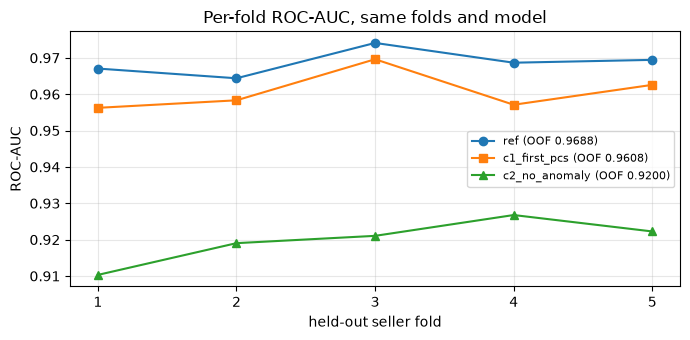

In [10]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 3.5))
for n, mk in [('ref', 'o'), ('c1_first_pcs', 's'), ('c2_no_anomaly', '^')]:
    ax.plot(range(1, 6), reports[n]['fold_roc_auc'], marker=mk, label=f"{n} (OOF {reports[n]['oof_roc_auc']:.4f})")
ax.set_xticks(range(1, 6)); ax.set_xlabel('held-out seller fold'); ax.set_ylabel('ROC-AUC')
ax.set_title('Per-fold ROC-AUC, same folds and model'); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT / 'comparisons_per_fold.png', dpi=150); plt.show()

## Where the difference comes from

Percentile rank of the positive listings in each configuration (1.0 = top of the review list). For
comparison 1 the subset of positives whose text quantity (team parser) disagrees with `pack_size` is
shown separately. This is a diagnostic on training labels only, not a claim about the hidden
corruption type of any listing.

In [11]:
xm = base_frame(train.drop(columns='target'), 'main_items')
pos = oofs['ref'].target == 1
rank = {n: oofs[n].prediction.rank(pct=True) for n in oofs}
diag = pd.DataFrame({
    'all positives': {n: rank[n][pos].mean() for n in rank},
    'positives with text/pack mismatch': {n: rank[n][pos & (xm.mvp_mismatch == 1)].mean() for n in rank},
})
display(diag.round(4))

,all positives,positives with text/pack mismatch
ref,0.8891,0.9650
c1_first_pcs,0.8825,0.8634
c2_no_anomaly,0.8486,0.9714


## Analysis of five out-of-fold errors (report Section 5.3)

**Reference model:** `ref`. **Decision rule:** a fixed review budget equal to the training error rate:
the 17.0% highest-scored listings are flagged. The threshold is the corresponding quantile of the OOF
scores, so only training and validation data are used.

**Case selection:** the two most confident false positives with different causes, the two most
confident false negatives, and the false negative closest to the threshold. We report what is
observed and what we infer, and we do not claim to know which field was corrupted.

In [12]:
from sklearn.metrics import confusion_matrix
oof = oofs['ref'].copy()
assert (oof.id.values == train.id.values).all()
thr = np.quantile(oof.prediction, 1 - train.target.mean())
oof['decision'] = (oof.prediction >= thr).astype(int)
tn, fp, fn, tp = confusion_matrix(oof.target, oof.decision).ravel()
print(f"threshold {thr:.4f} | flagged {oof.decision.sum()} | TN {tn} FP {fp} FN {fn} TP {tp} | "
      f"precision {tp / (tp + fp):.3f} recall {tp / (tp + fn):.3f}")

show = ['mvp_mismatch', 'main_items', 'free_acc', 'product_phrase', 'phrase_purity', 'cat_contradicts_strict',
        'price_item_z_pp2', 'weight_item_z_pp2', 'price_z_pc', 'weight_z_pc', 'rule_score']
D = pd.concat([train, oof[['prediction', 'decision', 'fold']], H[show]], axis=1)
cases = ['OFR_402507432', 'OFR_443298191', 'OFR_520815217', 'OFR_588855366', 'OFR_135113152']
C = D.set_index('id').loc[cases]
display(C[['fold', 'target', 'prediction', 'decision']].round(3))
pd.set_option('display.max_colwidth', 300)
display(C[['title', 'description', 'declared_category', 'brand', 'condition', 'price_pln', 'shipping_weight_kg', 'pack_size']])
display(C[show].round(3))

threshold 0.2403 | flagged 2721 | TN 12883 FP 396 FN 396 TP 2325 | precision 0.854 recall 0.854


,fold,target,prediction,decision
id,,,,
OFR_402507432,5,0,0.999,1
OFR_443298191,2,0,0.998,1
OFR_520815217,2,1,0.000,0
OFR_588855366,4,1,0.000,0
OFR_135113152,3,1,0.238,0


,title,description,declared_category,brand,condition,price_pln,shipping_weight_kg,pack_size
id,,,,,,,,
OFR_402507432,Velto B571: standard electric guitar connection lead (pack of two),Variant: standard. Also includes 3 pcs of free accessory pieces; these do not count as main items. Instrument cable by Velto. Pack of two main items. For practice or home music use. Dispatch from local stock.,audio,Velto,used,56.62,0.476,2.0
OFR_443298191,Velto laptop ventilation stand / standard / 1 pcs,NaN,computers,Velto,new,161.26,0.726,1.0
OFR_520815217,wet shave applicator — 1-pack — Tenso A464,Also includes 1 pcs of free accessory pieces; these do not count as main items. Shaving brush by Tenso. Variant: standard. Sold as a 1-pack. For personal care. Dispatch from local stock.,beauty,Tenso,refurbished,29.08,0.129,1.0
OFR_588855366,DIGITAL FOOD BALANCE — 1 UNITS — TENSO B873,Bundle quantity: 1 units. Kitchen scale by Tenso. Variant: standard. Clean according to the care instructions. Packed for delivery.,kitchen,Tenso,new,70.01,0.667,1.0
OFR_135113152,Aster plant growing guide / compact / quantity 1,"Variant: compact. Also includes 1 pcs of free accessory pieces; these do not count as main items. Gardening handbook by Aster. Included main items: 1. Physical book, not a digital download. Check dimensions before purchase.",books,Aster,new,54.88,1.581,NaN


,mvp_mismatch,main_items,free_acc,product_phrase,phrase_purity,cat_contradicts_strict,price_item_z_pp2,weight_item_z_pp2,price_z_pc,weight_z_pc,rule_score
id,,,,,,,,,,,
OFR_402507432,0,2.0,3,instrument cable,1.000,1,-1.411000e+00,-1.270,NaN,NaN,5.0
OFR_443298191,0,1.0,0,velto laptop ventilation stand,0.000,0,5.442000e+07,-202500.000,-5.242000e+07,-1131000.000,0.0
OFR_520815217,0,1.0,1,shaving brush,0.949,0,-8.090000e-01,-0.568,-1.051000e+00,-1.178,0.0
OFR_588855366,0,1.0,0,kitchen scale,0.938,0,1.202000e+00,3.498,3.770000e-01,1.711,0.0
OFR_135113152,0,1.0,1,gardening handbook,0.622,0,NaN,NaN,-1.270000e-01,4.439,0.0


In [13]:
fps = D[(D.decision == 1) & (D.target == 0)].sort_values('prediction', ascending=False)
fns = D[(D.decision == 0) & (D.target == 1)].sort_values('prediction')
near = D[D.decision != D.target].assign(dist=(D.prediction - thr).abs()).sort_values('dist')
print('most confident FP:', fps.id.head(3).tolist())
print('most confident FN:', fns.id.head(2).tolist())
print('errors closest to the threshold:', near[['id', 'target']].head(3).values.tolist())

zc = [c for c in H.columns if '_z_' in c]
huge = (H[zc].abs() > 1000).any(axis=1)
print(f"listings with an exploded z-score (abs > 1000): {int(huge.sum())}, of which false positives: {int((huge & (D.decision == 1) & (D.target == 0)).sum())} of {fp}")
quiet = (fns.price_item_z_pp2.abs() < 3) & (fns.weight_item_z_pp2.abs() < 3) & (fns.cat_contradicts_strict == 0) & (fns.mvp_mismatch == 0)
print(f"false negatives with no visible inconsistency: {int(quiet.sum())} of {fn}")
ic = D[D.product_phrase == 'instrument cable']
display(ic.groupby('declared_category').target.agg(error_rate='mean', listings='size'))

cat_auc = {c: roc_auc_score(g.target, g.prediction) for c, g in
           oof.assign(cat=train.declared_category.fillna('missing')).groupby('cat')}
display(pd.Series(cat_auc, name='OOF ROC-AUC').round(4).to_frame())

most confident FP: ['OFR_402507432', 'OFR_922090676', 'OFR_443298191']
most confident FN: ['OFR_520815217', 'OFR_588855366']
errors closest to the threshold: [['OFR_509373844', 0], ['OFR_135113152', 1], ['OFR_919452578', 0]]
listings with an exploded z-score (abs > 1000): 380, of which false positives: 70 of 396
false negatives with no visible inconsistency: 204 of 396


,error_rate,listings
declared_category,,
audio,0.000000,2
music,0.083333,12


,OOF ROC-AUC
audio,0.9708
beauty,0.9728
books,0.9695
computers,0.9724
garden,0.9731
kitchen,0.9651
missing,0.9359
music,0.9611
pets,0.9703
sport,0.9577


## Interpretation

Numbers below refer to the executed cells above (rounded). When rerun on Kaggle with its library
versions, the last digits may differ. The conclusions do not.

**Comparison 1 (quantity extraction).** The hypothesis holds. With the starter heuristic the pooled
OOF ROC-AUC drops from about 0.969 to 0.961 (−0.008, seller bootstrap interval about [−0.010,
−0.006]), and the drop appears in all five folds. The diagnostic explains why. `first_pcs` finds a
count in only about 37% of listings and flags 2,170 mismatches whose target rate (0.21) is barely
above the 0.17 base rate. Most of those flags are free-accessory counts. The team parser finds a count
in 99.9% of listings and flags 391 mismatches, all of them positive in training. Positives with a
text/pack mismatch fall from a mean percentile rank of about 0.965 to 0.863 when the noisy flag is
used.

The loss is modest overall because quantity mismatches are only a small part of the positives, and
the `phrase` group (modal pack size per product) partly compensates. One limitation shows up in the
reference too. Even with a perfect mismatch flag, those positives sit at a mean rank of 0.965 rather
than at the very top. The tree model does not turn a flag that is never wrong in training into a hard
rule, which is a candidate for a later experiment.

**Comparison 2 (price/weight anomaly group).** The hypothesis holds strongly. Removing the
product-relative z-scores lowers pooled OOF ROC-AUC from about 0.969 to 0.920 (−0.049, interval about
[−0.055, −0.043]) and average precision from 0.926 to 0.847, again in every fold. Raw log price and
weight cannot replace the group, because a price is only suspicious relative to the product it
belongs to. The group is the largest single contributor among those tested.

**Limitations.**
- Both comparisons reuse the reference configuration and the same five folds. The reference was not
  tuned against these folds, but the absolute OOF values are still slightly optimistic as a final
  estimate.
- The z-scores normalise only by product phrase (and product×declared category). Condition, variant,
  promotion and brand also shift prices in this data and are not modelled. Typos fragment the phrases
  (about 400 phrases for 90 product families), so some groups are small.
- Neither comparison is evidence about the corruption type of any single listing.